#### 06 · Segmentação de municípios por contexto educacional

Este notebook responde à pergunta do Tech Challenge sobre quais municípios apresentam condições semelhantes. O objetivo é criar grupos comparáveis para apoiar o desenho de intervenções territoriais.

O escopo foi reduzido ao necessário:

1. selecionar o retrato municipal mais recente;
2. preparar variáveis educacionais, socioeconômicas e territoriais;
3. escolher uma quantidade de grupos com silhueta e Davies-Bouldin;
4. ajustar K-Means;
5. utilizar PCA apenas para visualização e interpretação;
6. persistir a segmentação para análise no notebook seguinte.

Métodos adicionais que aumentavam o tempo, mas não eram necessários para responder ao desafio, foram retirados.


In [1]:
from pathlib import Path
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42


def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "src").exists():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
REPORTS = PROJECT_ROOT / "reports"
IMAGES = PROJECT_ROOT / "images"
REPORTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

from src.visualization.plot_style import (
    aplicar_estilo,
    salvar_figura,
    AZUL,
    LARANJA,
    VERDE,
    VERMELHO,
    CINZA,
    PALETA,
)
from src.visualization.business_labels import rotulo, rotular

aplicar_estilo()
pd.set_option("display.max_columns",100)
pd.set_option("display.width",180)

ARQ_MUNICIPIO = PROCESSED / "base_analitica_municipio.parquet"
if not ARQ_MUNICIPIO.exists():
    raise FileNotFoundError(ARQ_MUNICIPIO)

abt = pd.read_parquet(ARQ_MUNICIPIO)
abt["ano_alvo"] = pd.to_numeric(abt["ano_alvo"], errors="coerce").astype("Int64")
print(f"Base municipal: {abt.shape}")


Base municipal: (43788, 59)


##### 1. Retrato municipal mais recente


In [2]:
# Prefere o ano futuro mais recente com contexto disponível. Se não houver,
# utiliza o maior ano existente na base analítica.
contagem_por_ano = abt.groupby("ano_alvo").size().sort_index()
ANO_RETRATO = int(contagem_por_ano.index.max())
base = abt[abt["ano_alvo"].eq(ANO_RETRATO)].copy()

# O grão atual inclui rede. Para a política de metas, prioriza rede municipal;
# se essa categoria não existir, mantém o retrato disponível.
if "rede" in base.columns:
    rede_texto = base["rede"].astype("string").str.lower().str.strip()
    municipal = base[rede_texto.eq("municipal")].copy()
    if not municipal.empty:
        base = municipal

# Garante uma linha por município no retrato usado para agrupamento.
base = base.sort_values("id_municipio").drop_duplicates("id_municipio", keep="last").reset_index(drop=True)
print(f"Ano do retrato: {ANO_RETRATO}")
print(f"Municípios: {len(base):,}")


Ano do retrato: 2030
Municípios: 5,477


##### 2. Variáveis usadas na segmentação


In [3]:
CANDIDATAS = [
    # histórico e participação
    "indicador_t1",
    "participacao_t1",
    "salto_necessario",
    # IDEB e fluxo escolar disponíveis no projeto atual
    "ideb_ideb_observado_ultimo",
    "ideb_ideb_nota_portugues_ultimo",
    "ideb_ideb_nota_matematica_ultimo",
    "ideb_ideb_rendimento_ultimo",
    "ideb_aprovacao_ai_pct_ultimo",
    "ideb_aprovacao_1ano_pct_ultimo",
    "ideb_aprovacao_2ano_pct_ultimo",
    # contexto socioeconômico
    "media_inse",
    "qtd_alunos_inse",
    "populacao",
    "area_km2",
    "densidade_hab_km2",
    "pib_per_capita_reais",
    "participacao_vab_agro_pct",
    "participacao_vab_industria_pct",
    "participacao_vab_adm_publica_pct",
    "participacao_vab_servicos_pct",
]

variaveis = [c for c in CANDIDATAS if c in base.columns]

# Remove colunas sem nenhuma observação ou praticamente constantes.
variaveis = [
    c for c in variaveis
    if base[c].notna().any() and pd.to_numeric(base[c], errors="coerce").nunique(dropna=True) > 1
]

if len(variaveis) < 4:
    raise ValueError(f"Poucas variáveis disponíveis para segmentação: {variaveis}")

LOG_VARS = [
    c for c in ["populacao", "area_km2", "densidade_hab_km2", "pib_per_capita_reais", "qtd_alunos_inse"]
    if c in variaveis
]

x = base[variaveis].apply(pd.to_numeric, errors="coerce").copy()
for coluna in LOG_VARS:
    x[coluna] = np.log1p(x[coluna].clip(lower=0))

preprocessador = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
z = preprocessador.fit_transform(x)

print(f"Matriz: {z.shape[0]:,} municípios × {z.shape[1]} variáveis")
print(f"Valores imputados: {int(x.isna().sum().sum()):,}")
display(pd.DataFrame({"coluna":variaveis,"rótulo":rotular(variaveis),"transformação":["log1p" if c in LOG_VARS else "nenhuma" for c in variaveis]}))


Matriz: 5,477 municípios × 17 variáveis
Valores imputados: 1,318


,coluna,rótulo,transformação
0,ideb_ideb_observado_ultimo,IDEB mais recente,nenhuma
1,ideb_ideb_nota_portugues_ultimo,Nota de Portugues mais recente,nenhuma
2,ideb_ideb_nota_matematica_ultimo,Nota de Matematica mais recente,nenhuma
3,ideb_ideb_rendimento_ultimo,Rendimento do IDEB mais recente,nenhuma
4,ideb_aprovacao_ai_pct_ultimo,Aprovacao nos anos iniciais (%),nenhuma
5,ideb_aprovacao_1ano_pct_ultimo,Aprovacao no 1º ano (%),nenhuma
6,ideb_aprovacao_2ano_pct_ultimo,Aprovacao no 2º ano (%),nenhuma
7,media_inse,Nivel socioeconomico medio (INSE),nenhuma
8,qtd_alunos_inse,Alunos considerados no INSE,log1p
9,populacao,Populacao,log1p


##### 3. Quantidade de segmentos


,k,wcss,silhueta,davies_bouldin,menor_grupo
0,2,78237.256,0.182,2.064,2199
1,3,67376.107,0.178,1.716,1393
2,4,61154.715,0.167,1.649,501
3,5,56106.469,0.157,1.615,426
4,6,53045.108,0.156,1.612,225
5,7,50221.452,0.152,1.709,223


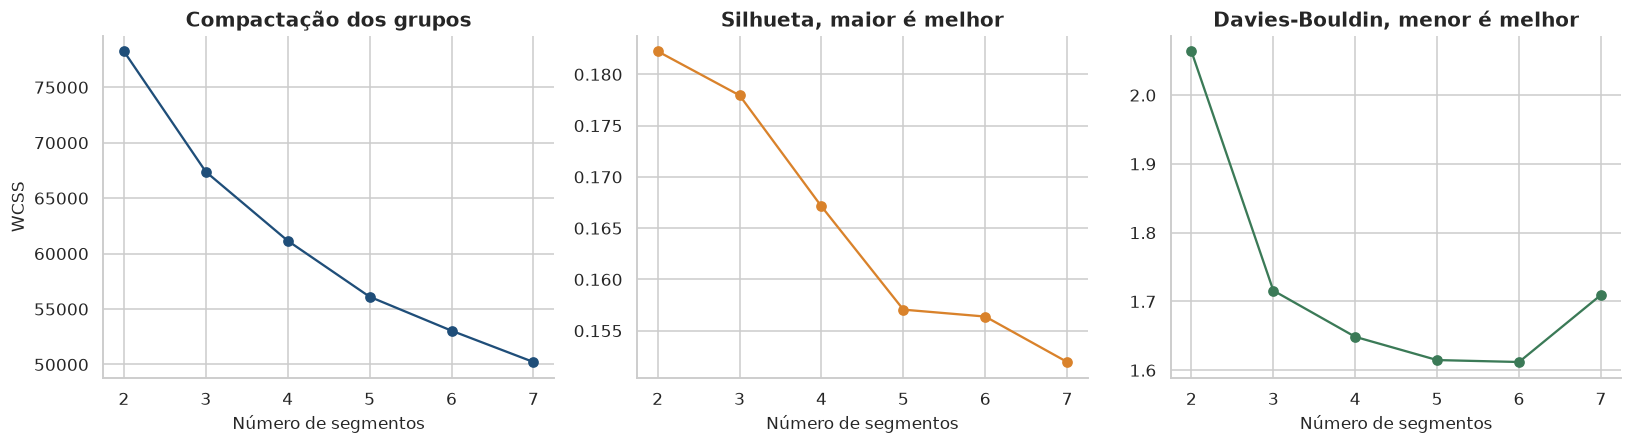

In [4]:
ks = range(2, 8)
avaliacao = []
tamanho_silhueta = min(3000, len(z))

for k in ks:
    km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    rotulos_k = km_k.fit_predict(z)
    avaliacao.append({
        "k": k,
        "wcss": km_k.inertia_,
        "silhueta": silhouette_score(
            z,
            rotulos_k,
            sample_size=tamanho_silhueta,
            random_state=SEED,
        ),
        "davies_bouldin": davies_bouldin_score(z, rotulos_k),
        "menor_grupo": int(pd.Series(rotulos_k).value_counts().min()),
    })

avaliacao = pd.DataFrame(avaliacao)
display(avaliacao.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(avaliacao["k"], avaliacao["wcss"], marker="o", color=AZUL)
axes[0].set_title("Compactação dos grupos")
axes[0].set_ylabel("WCSS")
axes[1].plot(avaliacao["k"], avaliacao["silhueta"], marker="o", color=LARANJA)
axes[1].set_title("Silhueta, maior é melhor")
axes[2].plot(avaliacao["k"], avaliacao["davies_bouldin"], marker="o", color=VERDE)
axes[2].set_title("Davies-Bouldin, menor é melhor")
for ax in axes:
    ax.set_xlabel("Número de segmentos")
salvar_figura(fig, "06_escolha_segmentos")
plt.show()


##### 4. Escolha reproduzível e ajuste do K-Means


In [5]:
# Seleciona a melhor silhueta entre soluções sem grupos muito pequenos.
# O limite mínimo evita segmentos que não sustentariam uma intervenção própria.
MIN_GRUPO = max(50, round(0.02 * len(base)))
elegiveis = avaliacao[avaliacao["menor_grupo"] >= MIN_GRUPO].copy()
if elegiveis.empty:
    elegiveis = avaliacao.copy()

K = int(
    elegiveis.sort_values(
        ["silhueta", "davies_bouldin"],
        ascending=[False, True],
    ).iloc[0]["k"]
)

modelo_segmentacao = KMeans(
    n_clusters=K,
    n_init=30,
    random_state=SEED,
)
base["segmento"] = modelo_segmentacao.fit_predict(z)

print(f"K escolhido: {K}")
print("Tamanho dos segmentos:")
display(base["segmento"].value_counts().sort_index().to_frame("municípios"))


K escolhido: 2
Tamanho dos segmentos:


,municípios
segmento,
0,3278
1,2199


##### 5. Visualização com PCA


Variância dos dois primeiros componentes: 47.9%
Componentes para 80%: 6


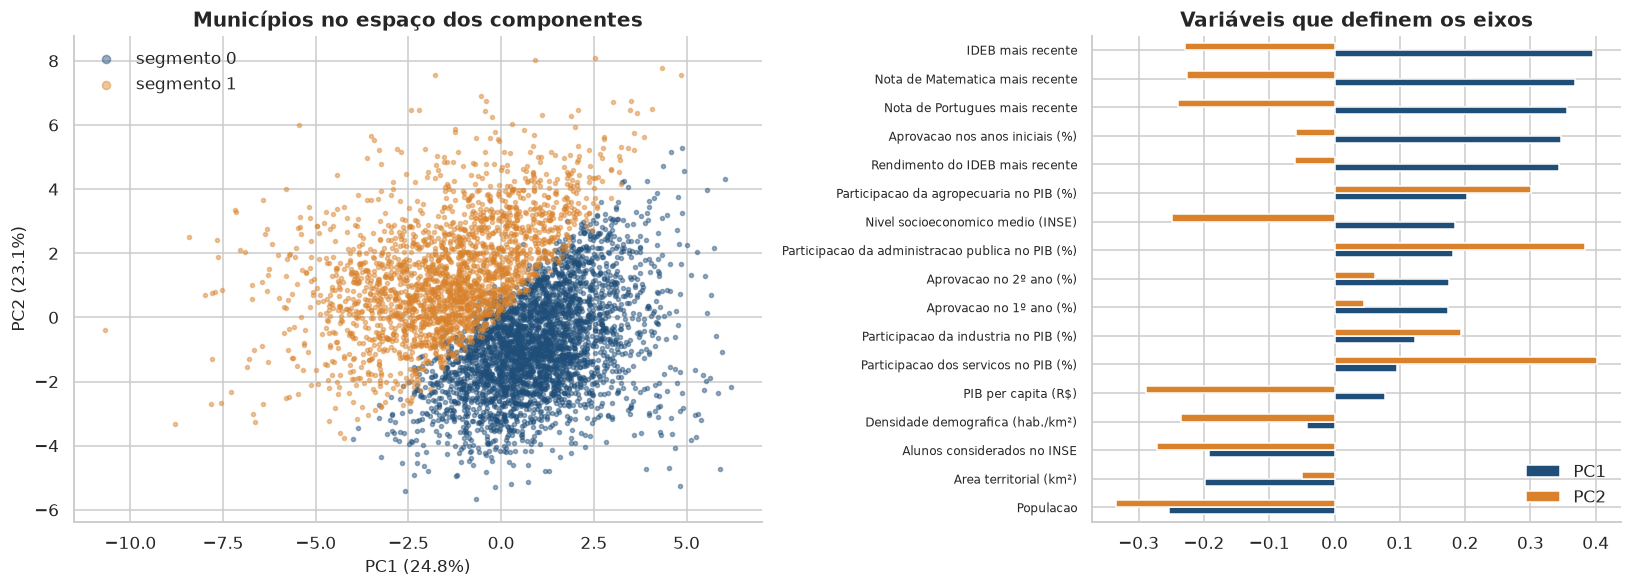

,PC1,PC2
Participacao dos servicos no PIB (%),0.096,0.402
IDEB mais recente,0.396,-0.228
Participacao da administracao publica no PIB (%),0.182,0.383
Nota de Matematica mais recente,0.369,-0.227
Nota de Portugues mais recente,0.356,-0.240
Aprovacao nos anos iniciais (%),0.346,-0.059
Rendimento do IDEB mais recente,0.344,-0.060
Populacao,-0.254,-0.335
Participacao da agropecuaria no PIB (%),0.203,0.301
PIB per capita (R$),0.078,-0.289


In [6]:
pca = PCA(random_state=SEED)
componentes = pca.fit_transform(z)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)

print(f"Variância dos dois primeiros componentes: {100 * variancia_acumulada[1]:.1f}%")
print(f"Componentes para 80%: {int(np.argmax(variancia_acumulada >= 0.8) + 1)}")

cargas = pd.DataFrame(
    pca.components_[:2].T,
    index=rotular(variaveis),
    columns=["PC1", "PC2"],
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios":[1.3,1]})
for segmento in sorted(base["segmento"].unique()):
    mascara = base["segmento"].eq(segmento).to_numpy()
    axes[0].scatter(
        componentes[mascara, 0],
        componentes[mascara, 1],
        s=7,
        alpha=0.45,
        color=PALETA[segmento % len(PALETA)],
        label=f"segmento {segmento}",
    )
axes[0].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)")
axes[0].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
axes[0].set_title("Municípios no espaço dos componentes")
axes[0].legend(markerscale=2)

cargas.sort_values("PC1").plot.barh(ax=axes[1], color=[AZUL,LARANJA])
axes[1].set_title("Variáveis que definem os eixos")
axes[1].tick_params(axis="y", labelsize=8)
salvar_figura(fig, "06_pca_segmentos")
plt.show()

display(cargas.reindex(cargas.abs().max(axis=1).sort_values(ascending=False).index).head(12).round(3))


##### 6. Persistência da segmentação


In [7]:
MODELS.mkdir(exist_ok=True)
artefato = {
    "ano_retrato": ANO_RETRATO,
    "features": variaveis,
    "log_features": LOG_VARS,
    "preprocessador": preprocessador,
    "modelo": modelo_segmentacao,
    "pca": pca,
    "avaliacao_k": avaliacao,
}
joblib.dump(artefato, MODELS / "segmentacao_municipios.joblib", compress=3)

colunas_saida = [c for c in [
    "ano_alvo", "id_municipio", "nome_municipio", "sigla_uf", "nome_regiao", "rede", "segmento"
] if c in base.columns]
segmentacao = base[colunas_saida].copy()
segmentacao.to_csv(REPORTS / "segmentacao_municipios.csv", index=False, encoding="utf-8-sig")
segmentacao.to_parquet(REPORTS / "segmentacao_municipios.parquet", index=False)

avaliacao.to_csv(REPORTS / "avaliacao_segmentacao.csv", index=False)

print("Artefatos salvos:")
print("- models/segmentacao_municipios.joblib")
print("- reports/segmentacao_municipios.csv")
print("- reports/avaliacao_segmentacao.csv")


Artefatos salvos:
- models/segmentacao_municipios.joblib
- reports/segmentacao_municipios.csv
- reports/avaliacao_segmentacao.csv


#### Resumo do Notebook 06 · Segmentação de Municípios

O notebook agrupou municípios com condições educacionais, socioeconômicas e territoriais semelhantes, usando imputação, padronização, K-Means e PCA.

##### Resultados numéricos

- **Municípios analisados:** 5.477
- **Ano do retrato utilizado:** 2030
- **Variáveis selecionadas:** 17
- **Valores ausentes imputados:** 1.318
- **Número de segmentos escolhido:** 2

| Segmento | Municípios |
|---|---:|
| Segmento 0 | 3.278 |
| Segmento 1 | 2.199 |

##### Avaliação do agrupamento escolhido

| Métrica | K = 2 |
|---|---:|
| Silhueta | **0,182** |
| Davies-Bouldin | **2,064** |
| WCSS | **78.237** |
| Menor grupo | **2.199 municípios** |

A silhueta relativamente baixa indica que os municípios formam um espaço contínuo, sem fronteiras naturais muito fortes. Mesmo assim, o K = 2 produziu grupos grandes e operacionalmente utilizáveis.

##### PCA

- Os dois primeiros componentes explicam **47,9% da variância**.
- São necessários **6 componentes** para alcançar 80% da variância.

As variáveis com maior participação na separação incluem:

- IDEB mais recente: PC1 = **0,396**;
- nota de Matemática: PC1 = **0,369**;
- nota de Português: PC1 = **0,356**;
- população: PC1 = **-0,254** e PC2 = **-0,335**;
- INSE médio: PC2 = **-0,249**;
- participação dos serviços no PIB: PC2 = **0,402**.

##### Conclusões

- Os municípios foram organizados em **dois grandes segmentos**, com 3.278 e 2.199 integrantes.
- A separação é explicada principalmente por desempenho educacional, nível socioeconômico, população e composição econômica.
- Os dois primeiros componentes do PCA resumem menos da metade da variância, mostrando que os perfis municipais são multidimensionais.
- Os segmentos devem ser interpretados como **recortes operacionais**, úteis para comparação entre municípios semelhantes e desenho de políticas, não como categorias naturais ou definitivas.
- A etapa seguinte deve descrever os dois segmentos em linguagem de negócio e cruzá-los com o risco municipal.

> **Síntese:** a segmentação encontrou dois perfis amplos e equilibrados, mas as métricas mostram fronteiras difusas. O agrupamento é útil para orientar políticas por contexto, desde que não seja tratado como uma divisão rígida entre municípios.
